## Q1

In [2]:
import pandas as pd

# Load the market data (one row = one selling period)
df = pd.read_csv("data/coffee_market.csv")

print(df.shape)          # number of rows and columns
print(df.head())         # first 5 rows
print(df.describe())     # min, max, mean, ... per column
print(df.isna().sum())   # missing values per column

(300, 6)
  period_id  period_index  price_usd_kg  quantity_kt  growing_conditions  \
0      M001             1     10.837531   133.302350                 1.5   
1      M002             2      8.915661    67.150820                -1.5   
2      M003             3     11.694981    88.019068                -1.5   
3      M004             4     10.394216   101.971595                 0.0   
4      M005             5      7.323098    95.714836                 1.5   

   buyer_activity  
0        2.391855  
1       -2.516137  
2       -0.195789  
3        0.117742  
4       -1.148320  
       period_index  price_usd_kg  quantity_kt  growing_conditions  \
count    300.000000    300.000000   300.000000          300.000000   
mean     150.500000     10.007071   100.014193            0.000000   
std       86.746758      2.216562    18.463413            1.226791   
min        1.000000      5.167537    64.153291           -1.500000   
25%       75.750000      8.498644    85.272858           -1.5000

In [3]:
print(df["growing_conditions"].value_counts())

growing_conditions
 1.5    100
-1.5    100
 0.0    100
Name: count, dtype: int64


/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_94304/844172299.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["revenue_musd"] = df["price_usd_kg"] * df["quantity_kt"]


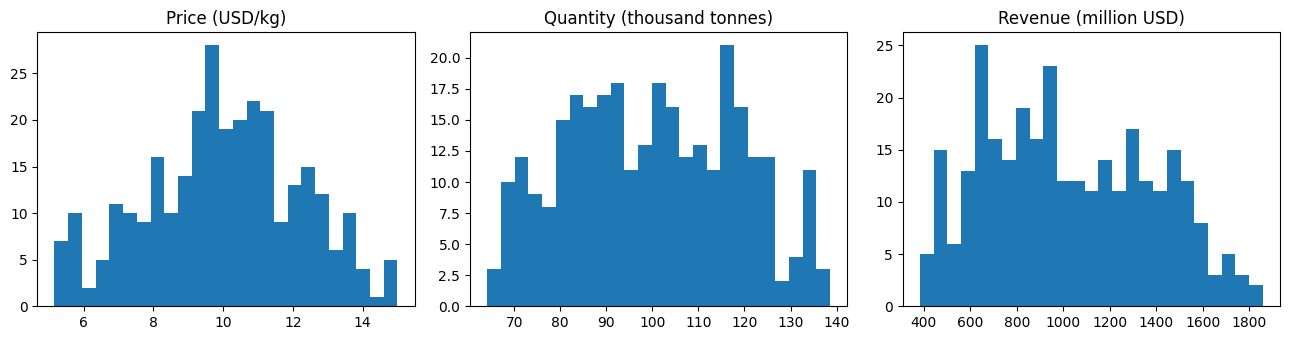

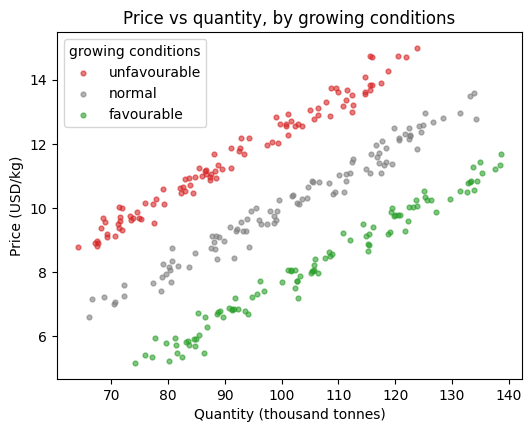

              price_usd_kg  quantity_kt
price_usd_kg      1.000000     0.538858
quantity_kt       0.538858     1.000000


In [5]:
import matplotlib.pyplot as plt

# Revenue per selling period, in million USD
df["revenue_musd"] = df["price_usd_kg"] * df["quantity_kt"]

# Three histograms next to each other: price, quantity, revenue
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(df["price_usd_kg"], bins=25)
axes[0].set_title("Price (USD/kg)")
axes[1].hist(df["quantity_kt"], bins=25)
axes[1].set_title("Quantity (thousand tonnes)")
axes[2].hist(df["revenue_musd"], bins=25)
axes[2].set_title("Revenue (million USD)")
plt.tight_layout()
plt.show()

# scatter, but one colour per growing-conditions group
colors = {-1.5: "tab:red", 0.0: "tab:gray", 1.5: "tab:green"}
labels = {-1.5: "unfavourable", 0.0: "normal", 1.5: "favourable"}

fig, ax = plt.subplots(figsize=(6, 4.5))
for value in [-1.5, 0.0, 1.5]:
    group = df[df["growing_conditions"] == value]
    ax.scatter(group["quantity_kt"], group["price_usd_kg"], s=12, alpha=0.6,
               color=colors[value], label=labels[value])
ax.set_xlabel("Quantity (thousand tonnes)")
ax.set_ylabel("Price (USD/kg)")
ax.set_title("Price vs quantity, by growing conditions")
ax.legend(title="growing conditions")
plt.show()

# Correlation between price and quantity
print(df[["price_usd_kg", "quantity_kt"]].corr())

##### Finding (Q1).

The 300 selling periods are split evenly over three levels of growing conditions: 100 unfavourable (low), 100 normal (medium) and 100 favourable (high). Overall, price and quantity move together: when the price is higher, the quantity is usually higher too (correlation ≈ 0.54).

The scatter shows three separate groups of points, one for each level of growing conditions. In unfavourable conditions, prices are higher and quantities lower. In favourable conditions, prices are lower and quantities higher. Within each group, a higher price goes with a higher quantity. This fits sellers who want to sell more when the price is higher.

Each point is a market equilibrium: the price and quantity where demand and supply meet in that period. Both curves can move. Supply moves with growing conditions, and demand moves with buyer activity and with things we do not observe. The overall relationship therefore mixes the two, so it is not a demand curve. It does not tell us how buyers would react if the price went up. To find that out, we need something that moves supply while demand stays comparable.

## Q2


In [6]:
# Is buyer activity similar in the three growing-conditions groups?
balance = df.groupby("growing_conditions")["buyer_activity"].agg(["mean", "std", "count"])
print(balance.round(2))

                    mean   std  count
growing_conditions                   
-1.5               -0.07  1.69    100
 0.0                0.20  1.67    100
 1.5               -0.15  1.76    100


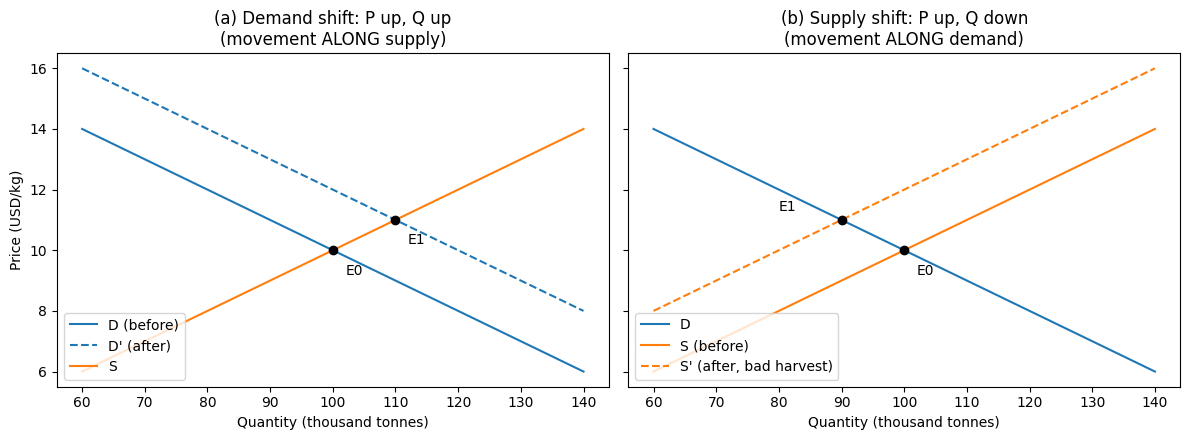

In [7]:
import numpy as np
import matplotlib.pyplot as plt

q = np.linspace(60, 140, 100)        # quantity axis (thousand tonnes)

def demand(q, shift=0):
    # downward-sloping demand: price falls as quantity rises
    return 20 - 0.1 * q + shift

def supply(q, shift=0):
    # upward-sloping supply: price rises as quantity rises
    return 0 + 0.1 * q + shift

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# (a) Demand shifts right, supply stays the same
ax = axes[0]
ax.plot(q, demand(q), color="tab:blue", label="D (before)")
ax.plot(q, demand(q, 2), color="tab:blue", ls="--", label="D' (after)")
ax.plot(q, supply(q), color="tab:orange", label="S")
ax.plot(100, 10, "ko"); ax.annotate("E0", (100, 10), (102, 9.2))
ax.plot(110, 11, "ko"); ax.annotate("E1", (110, 11), (112, 10.2))
ax.set_title("(a) Demand shift: P up, Q up\n(movement ALONG supply)")

# (b) Supply shifts left, demand stays the same
ax = axes[1]
ax.plot(q, demand(q), color="tab:blue", label="D")
ax.plot(q, supply(q), color="tab:orange", label="S (before)")
ax.plot(q, supply(q, 2), color="tab:orange", ls="--", label="S' (after, bad harvest)")
ax.plot(100, 10, "ko"); ax.annotate("E0", (100, 10), (102, 9.2))
ax.plot(90, 11, "ko"); ax.annotate("E1", (90, 11), (80, 11.3))
ax.set_title("(b) Supply shift: P up, Q down\n(movement ALONG demand)")

for ax in axes:
    ax.set_xlabel("Quantity (thousand tonnes)")
    ax.legend(loc="lower left")
axes[0].set_ylabel("Price (USD/kg)")
plt.tight_layout()
plt.show()

##### Finding (Q2).

Each point is a market equilibrium: the price and quantity where demand and supply meet in that period. A higher price can have two causes. If demand shifts right (buyers want more), price and quantity both rise, and the market moves along the supply curve. If supply shifts left (a bad harvest), price rises but quantity falls, and the market moves along the demand curve. So quantity tells us the cause. In our data, buyer activity shifts demand within each group, which traces the upward supply curve, and the harvest shifts supply between groups, which traces the downward demand curve.

To learn how buyers respond to price, we compare favourable and unfavourable growing conditions. Supply shifts between these groups, but demand should be the same on average, so the difference in average price and quantity traces the demand curve. The normal group is a check: it should lie close to the line between the other two.

This rests on the assumptions in the brief: growing conditions are unrelated to buyers' demand, and buyer activity does not affect producers' costs. We also assume price-taking, market clearing, fixed quality and no storage. We can check part of this: average buyer activity is similar in all three groups (−0.07, 0.20 and −0.15).

Demand also moves for reasons we do not observe. That is fine as long as these shocks are unrelated to growing conditions. They are then the same on average in every group, so they cancel out in the comparison. They only add noise, and with 100 periods per group that noise mostly averages out.

## Q3

In [8]:
# Average price and quantity in each growing-conditions group
means = df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
print(means.round(2))

                    price_usd_kg  quantity_kt
growing_conditions                           
-1.5                       11.57        91.69
 0.0                       10.20       102.04
 1.5                        8.25       106.31


In [9]:
print(df.groupby("growing_conditions")["revenue_musd"].mean().round(0))

growing_conditions
-1.5    1089.0
 0.0    1070.0
 1.5     909.0
Name: revenue_musd, dtype: float64


In [10]:
import numpy as np

# Naive line: fit one straight line through ALL 300 points (quantity on price)
naive_slope, naive_intercept = np.polyfit(df["price_usd_kg"], df["quantity_kt"], 1)
print(f"Naive slope: {naive_slope:.2f} kt per USD/kg")

# Our comparison (favourable vs unfavourable)
means = df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
our_slope = (means.loc[1.5, "quantity_kt"] - means.loc[-1.5, "quantity_kt"]) / \
            (means.loc[1.5, "price_usd_kg"] - means.loc[-1.5, "price_usd_kg"])
print(f"Our slope:   {our_slope:.2f} kt per USD/kg")

Naive slope: 4.49 kt per USD/kg
Our slope:   -4.40 kt per USD/kg


Treating all 300 points alike gives a slope of +4.5 kt per USD/kg: the wrong sign for a demand curve. Most of the variation within each group comes from demand shifts, which trace the upward supply curve. Only the comparison across growing conditions isolates movements along demand (−4.4 kt per USD/kg).

In [11]:
import statsmodels.formula.api as smf

# For Q and for P: estimate group averages while holding buyer activity fixed.
# C(growing_conditions) gives each group its own level;
# buyer_activity takes out the part caused by more or less active buyers.
model_q = smf.ols("quantity_kt ~ C(growing_conditions) + buyer_activity", data=df).fit()
model_p = smf.ols("price_usd_kg ~ C(growing_conditions) + buyer_activity", data=df).fit()

# Predict Q and P for each group at buyer_activity = 0 (reference conditions)
grid = pd.DataFrame({"growing_conditions": [-1.5, 0.0, 1.5], "buyer_activity": [0, 0, 0]})
grid["Q_adjusted"] = model_q.predict(grid)
grid["P_adjusted"] = model_p.predict(grid)
print(grid.round(2))

# Slope again, now with adjusted means (high vs low)
low, high = grid.iloc[0], grid.iloc[2]
adj_slope = (high["Q_adjusted"] - low["Q_adjusted"]) / (high["P_adjusted"] - low["P_adjusted"])
print(f"Adjusted slope: {adj_slope:.2f} kt per USD/kg")

   growing_conditions  buyer_activity  Q_adjusted  P_adjusted
0                -1.5               0       92.37       11.64
1                 0.0               0      100.01       10.00
2                 1.5               0      107.84        8.40
Adjusted slope: -4.78 kt per USD/kg


/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_94304/443031114.py:11: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  grid["Q_adjusted"] = model_q.predict(grid)
/var/folders/t9/0f6k77l54153159xk5l1vz_80000gn/T/ipykernel_94304/44303

In [12]:
# ---- 1) Raw elasticity: from the plain group means ----------------------------
# Midpoint between unfavourable (-1.5) and favourable (1.5) conditions
P_mid_raw = (means.loc[-1.5, "price_usd_kg"] + means.loc[1.5, "price_usd_kg"]) / 2
Q_mid_raw = (means.loc[-1.5, "quantity_kt"] + means.loc[1.5, "quantity_kt"]) / 2

# Elasticity = slope x (P / Q), evaluated at the midpoint
elasticity_raw = our_slope * P_mid_raw / Q_mid_raw

# ---- 2) Adjusted elasticity: from the means at buyer_activity = 0 -------------
P_mid_adj = (low["P_adjusted"] + high["P_adjusted"]) / 2
Q_mid_adj = (low["Q_adjusted"] + high["Q_adjusted"]) / 2

elasticity_adj = adj_slope * P_mid_adj / Q_mid_adj

# ---- 3) Show both side by side -------------------------------------------------
results = pd.DataFrame({
    "slope (kt per USD/kg)": [our_slope, adj_slope],
    "midpoint price (USD/kg)": [P_mid_raw, P_mid_adj],
    "midpoint quantity (kt)": [Q_mid_raw, Q_mid_adj],
    "elasticity": [elasticity_raw, elasticity_adj],
}, index=["raw group means", "adjusted for buyer activity"])

print(results.round(2))

                             slope (kt per USD/kg)  midpoint price (USD/kg)  \
raw group means                              -4.40                     9.91   
adjusted for buyer activity                  -4.78                    10.02   

                             midpoint quantity (kt)  elasticity  
raw group means                               99.00       -0.44  
adjusted for buyer activity                  100.11       -0.48  


Buyer activity is slightly different across the groups, and highest in the normal group. If we hold it at zero, the slope changes from −4.4 to −4.8 kt per USD/kg (elasticity −0.44 to −0.48). The conclusion stays the same: demand slopes down and is inelastic. After this correction the normal group also lies closer to the line between the other two, so a straight line is a fair approximation over this range.

In [13]:
# Mean and standard error of price and quantity per group
# (standard error = how much the mean would move in a new sample)
summary = df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].agg(["mean", "sem"])
print(summary.round(2))

                   price_usd_kg       quantity_kt      
                           mean   sem        mean   sem
growing_conditions                                     
-1.5                      11.57  0.17       91.69  1.66
 0.0                      10.20  0.17      102.04  1.76
 1.5                       8.25  0.18      106.31  1.81


##### Finding (Q3).

Comparing favourable and unfavourable growing conditions, the price is 3.3 USD/kg lower with a good harvest (8.25 vs 11.57) and buyers take 14.6 thousand tonnes more (106.3 vs 91.7). That gives a demand slope of about −4.4: if the price goes up by 1 USD/kg, buyers buy about 4.4 thousand tonnes less. At the midpoint (P ≈ 9.9, Q ≈ 99) the elasticity is about −0.44, so a 1% higher price means about 0.44% less coffee sold.

Demand is inelastic, so a bad harvest raises market revenue: on average 1,089 million USD in unfavourable conditions vs 909 million USD in favourable ones.

As shown above, the naive line through all points has the wrong sign, and correcting for buyer activity barely changes the result. Each group mean is based on 100 periods and is quite precise, so a reasonable range is a slope of −4.4 to −4.8 and an elasticity of −0.44 to −0.48.

This relies on growing conditions being unrelated to what buyers want, buyer activity not affecting producers' costs, and no storage. The estimate only holds within the observed price range (about 5–15 USD/kg).